# 06 - Query-based detectors (RT-DETR and D-FINE)

RT-DETR-l (Zhao et al., 2023, arXiv:2304.08069) from Ultralytics, COCO weights, trained with the
same protocol as the anchor-free runs in notebook 05: fit on folds 1-2 (every 10th frame,
ignored regions masked), 30 epochs, 1152 px, same seed and augmentation, evaluated by our COCO
evaluator on the original fold-0 and `val` frames.

**How bipartite matching removes NMS.** YOLO assigns several grid locations to each object
(task-aligned top-k), so after training several neighbouring predictions fire on the same
object and NMS has to delete the copies. RT-DETR predicts a fixed set of queries and the
Hungarian matcher assigns each ground-truth object to exactly one query (cost = 2 x focal class
cost + 5 x L1 + 2 x GIoU); every other query is trained as "no object". A query that duplicates
an already matched one is therefore penalised during training, and the decoder self-attention
lets queries see each other, so the network itself learns to output one box per object.

**How this changes training.** One positive per object (instead of about ten) gives a sparse
and, early in training, unstable signal: the matching of a query can switch between epochs.
RT-DETR adds denoising queries (noisy copies of ground-truth boxes that must be reconstructed,
DN-DETR) and auxiliary losses after every decoder layer to stabilise it. DETR-style models are
known to converge more slowly than dense CNN detectors.

| Run | Change against the previous step |
|---|---|
| qb0_rtdetr_l_1152 | RT-DETR-l, Ultralytics defaults (AdamW, lr 8.3e-4 for all parameters), 300 queries |
| qb1_bblr_1152 | paper recipe: lr 1e-4, backbone lr 0.1x, weight decay 1e-4 |
| qb2_q500_1152 | qb1 with 500 queries instead of 300 |
| qb3_bblr_nobiaswarm_1152 | qb1 without the bias warm-up (see below) |
| qb4_q500_default_1152 | qb0 with 500 queries instead of 300 |

**Bias warm-up.** During the warm-up Ultralytics raises every learning rate from 0 to lr0,
except the biases, which fall from `warmup_bias_lr` = 0.1 to lr0. With `optimizer=auto` (qb0
and all YOLO runs) it sets `warmup_bias_lr` to 0 because it picks AdamW; with `optimizer: AdamW`
written in the config (qb1, qb2) the value stays 0.1, and the biases are trained with AdamW at
lr 0.067 in epoch 1 and 0.033 in epoch 2 (column `lr/pg4` of `results.csv`), about 700 times the
intended 1e-4. qb1 and qb2 are kept as a failed attempt; qb3 and qb4 are the clean versions of
the two questions they were meant to answer.

**D-FINE (qb5-qb7).** D-FINE (Peng et al., 2024, arXiv:2410.13842) keeps the RT-DETR design
(HGNetv2 backbone, hybrid encoder, one-to-one matching, no NMS) and changes how a box is
regressed. Every decoder layer predicts a probability distribution over the offsets of each box
edge and refines the distribution of the previous layer (fine-grained distribution refinement),
and the distributions of the last layer are distilled into the earlier layers (GO-LSD). The
checkpoints are pretrained on Objects365 and then COCO, RT-DETR-l only on COCO. Ultralytics does
not support D-FINE, so it runs through Hugging Face Transformers with its own data loading and
training loop (`src/dfine.py`).

| Run | Change |
|---|---|
| qb5_dfine_l_1152 | D-FINE-L (31M parameters): AdamW, lr 1e-4, backbone lr 0.1x, weight decay 1.25e-4, batch 2 x 4 accumulated, 6 epochs, moving average of the weights; random flip, zoom crop (window of 50-100% of the frame side) and colour jitter instead of mosaic |
| qb6_dfine_x_1152 | qb5 with D-FINE-X (62M parameters), batch 1 x 8 to fit in 8 GB |
| qb7_dfine_x_crop035 | qb6 with crops down to 35% of the frame side |

The D-FINE runs use every 5th frame of folds 1-2 (3243 frames, the data of p2 in notebook 07) for
6 epochs, about 40% of the iterations of qb0-qb4. They have no validation after every epoch, the
weights of the last epoch are scored.

In [1]:
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.analysis import classify_errors, error_summary, paired_comparison, per_clip_ap
from src.common import CLASS_NAMES, REPO_ROOT, RUNS_DIR
from src.evaluate import coco_evaluate
from src.predict import EVAL_SETS
from src.train_tools import load_config

# Anchor-free runs trained with the same budget, used as the CNN reference
REFERENCE_RUNS = ["af1_imgsz1152", "af4_topk5_1152"]
pd.set_option("display.precision", 4)

D:\Studying_2027_1\Artificial_Intelligence\cv-object-detection\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1108 19:01:45.874000 39488 .venv\Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


## 1. Results on fold 0 and val

In [2]:
def load_runs(family):
    found = {}
    for config_path in sorted((REPO_ROOT / "configs" / family).glob("*.yaml")):
        cfg = load_config(config_path)
        run_dir = RUNS_DIR / family / cfg["name"]
        if (run_dir / "metrics.json").exists():
            found[cfg["name"]] = {"cfg": cfg, "dir": run_dir,
                                  "metrics": json.loads((run_dir / "metrics.json").read_text())}
    return found


query_runs = load_runs("query_based")
anchor_free_runs = {k: v for k, v in load_runs("anchor_free").items() if k in REFERENCE_RUNS}
runs = {**anchor_free_runs, **query_runs}
print("query-based runs:", list(query_runs))

main_cols = ["AP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR_500"]
rows = []
for name, run in runs.items():
    fold0, val = run["metrics"]["fold0"], run["metrics"]["val"]
    rows.append({"run": name, **{c: fold0[c] for c in main_cols},
                 "val_AP": val["AP"], "val_AP50": val["AP50"], "ms_per_image": val["ms_per_image"]})
results = pd.DataFrame(rows).set_index("run")
results

query-based runs: ['qb0_rtdetr_l_1152', 'qb1_bblr_1152', 'qb2_q500_1152', 'qb3_bblr_nobiaswarm_1152', 'qb4_q500_default_1152', 'qb5_dfine_l_1152', 'qb6_dfine_x_1152', 'qb7_dfine_x_crop035']


,AP,AP50,AP75,AP_small,AP_medium,AP_large,AR_500,val_AP,val_AP50,ms_per_image
run,,,,,,,,,,
af1_imgsz1152,0.2343,0.4323,0.2256,0.0671,0.1836,0.3489,0.3796,0.1877,0.3746,28.7990
af4_topk5_1152,0.2378,0.4430,0.2285,0.0699,0.1819,0.3552,0.3899,0.1982,0.3851,27.4198
qb0_rtdetr_l_1152,0.2957,0.5434,0.2816,0.0842,0.2250,0.4232,0.4856,0.2534,0.4844,58.3827
qb1_bblr_1152,0.1746,0.3236,0.1731,0.0449,0.1412,0.2431,0.4227,0.1523,0.2928,59.3231
qb2_q500_1152,0.2111,0.3910,0.2079,0.0520,0.1664,0.2938,0.4793,0.1696,0.3337,60.2580
qb3_bblr_nobiaswarm_1152,0.2988,0.5407,0.2896,0.0826,0.2404,0.3940,0.5015,0.2621,0.4970,58.7423
qb4_q500_default_1152,0.3038,0.5433,0.2950,0.0777,0.2378,0.4356,0.5021,0.2374,0.4523,58.2475
qb5_dfine_l_1152,0.3308,0.5861,0.3204,0.0985,0.2772,0.4628,0.5461,0.2933,0.5556,139.1746
qb6_dfine_x_1152,0.3406,0.5959,0.3354,0.0941,0.3056,0.4909,0.5360,0.3167,0.5754,124.2218


## 2. Validation mAP during training: RT-DETR against YOLO11

Ultralytics mAP@[.5:.95] after every epoch on every 20th fold-0 frame. Left: against epochs
(same number of passes over the data). Right: against training time on the same GPU, which is
the real compute budget.

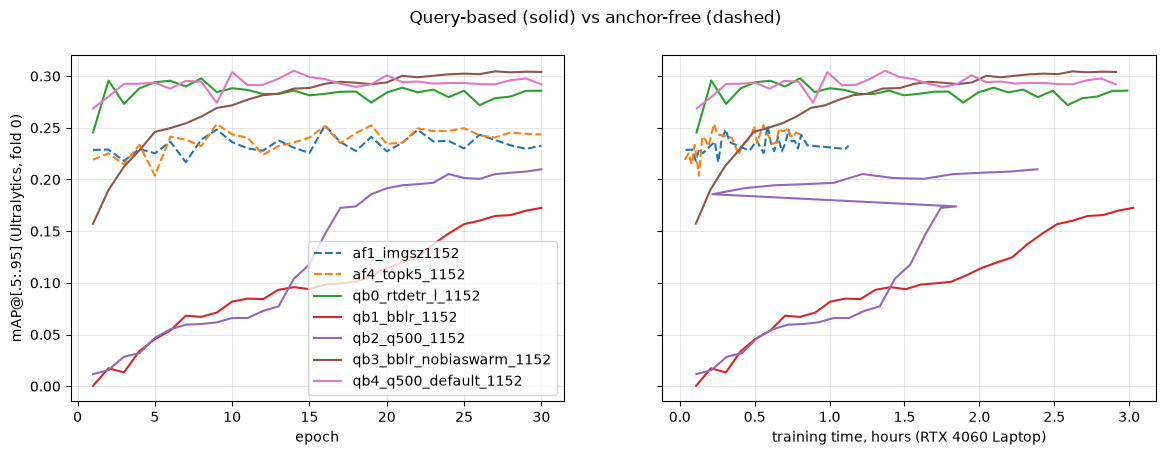

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
# Only Ultralytics runs are validated after every epoch
for name, run in runs.items():
    if not (run["dir"] / "results.csv").exists():
        continue
    curve = pd.read_csv(run["dir"] / "results.csv")
    curve.columns = curve.columns.str.strip()
    style = "--" if name in anchor_free_runs else "-"
    axes[0].plot(curve["epoch"], curve["metrics/mAP50-95(B)"], style, label=name)
    axes[1].plot(curve["time"] / 3600, curve["metrics/mAP50-95(B)"], style, label=name)
axes[0].set_xlabel("epoch")
axes[1].set_xlabel("training time, hours (RTX 4060 Laptop)")
axes[0].set_ylabel("mAP@[.5:.95] (Ultralytics, fold 0)")
axes[0].legend()
for ax in axes:
    ax.grid(alpha=0.3)
plt.suptitle("Query-based (solid) vs anchor-free (dashed)")
plt.show()

## 3. Small objects and dense scenes

AP by COCO size, and AP on fold-0 frames grouped by the number of annotated objects in the
frame. Dense frames are where a fixed set of queries could become a limit.

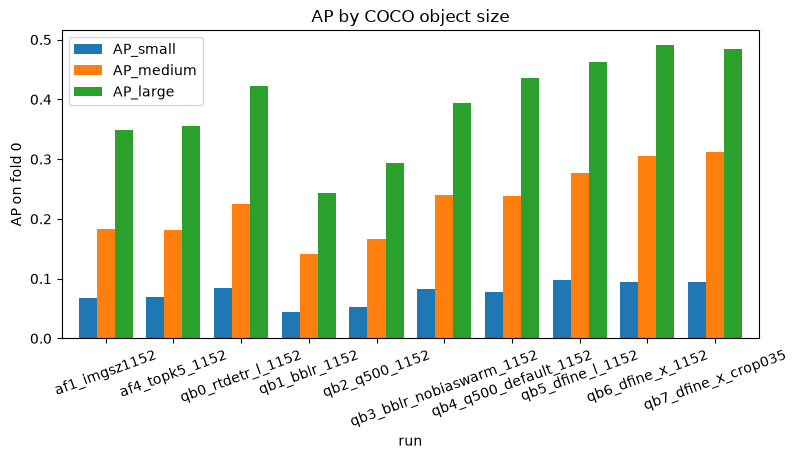

,person,bicycle,car,van,truck,tricycle,bus,motor
af1_imgsz1152,0.2103,0.0438,0.5009,0.1882,0.1315,0.2354,0.4483,0.1161
af4_topk5_1152,0.2189,0.0544,0.4962,0.1699,0.2075,0.1956,0.4317,0.1284
qb0_rtdetr_l_1152,0.2488,0.0989,0.5288,0.2180,0.2833,0.3031,0.5374,0.1472
qb1_bblr_1152,0.1540,0.0311,0.4364,0.1605,0.1488,0.1202,0.2820,0.0634
qb2_q500_1152,0.1811,0.0652,0.4715,0.1875,0.1314,0.1617,0.4005,0.0902
qb3_bblr_nobiaswarm_1152,0.2449,0.0998,0.5321,0.2409,0.2530,0.2952,0.5744,0.1504
qb4_q500_default_1152,0.2326,0.0918,0.5238,0.2783,0.3051,0.2872,0.5513,0.1601
qb5_dfine_l_1152,0.2617,0.1254,0.5485,0.2666,0.3437,0.3085,0.6076,0.1841
qb6_dfine_x_1152,0.2558,0.1312,0.5510,0.2912,0.3476,0.3184,0.6419,0.1876
qb7_dfine_x_crop035,0.2523,0.1297,0.5508,0.2796,0.3618,0.3391,0.6383,0.1806


In [4]:
size_cols = ["AP_small", "AP_medium", "AP_large"]
ax = results[size_cols].plot.bar(figsize=(9, 4), width=0.8)
ax.set_ylabel("AP on fold 0")
ax.set_title("AP by COCO object size")
ax.tick_params(axis="x", rotation=20)
plt.show()

per_class = pd.DataFrame({name: {c: run["metrics"]["fold0"][f"AP_{c}"] for c in CLASS_NAMES}
                          for name, run in runs.items()}).T
per_class

In [5]:
gt_path = EVAL_SETS["fold0"][1]
gt = json.loads(gt_path.read_text())
objects_per_image = pd.Series(0, index=[img["id"] for img in gt["images"]])
for ann in gt["annotations"]:
    if not ann["iscrowd"]:
        objects_per_image[ann["image_id"]] += 1

density_bins = [0, 20, 50, 100, np.inf]
density_names = ["<20", "20-50", "50-100", ">=100"]
density = pd.cut(objects_per_image, density_bins, labels=density_names, right=False)

density_rows = {}
for name, run in runs.items():
    detections = json.loads((run["dir"] / "predictions_fold0.json").read_text())
    density_rows[name] = {group: coco_evaluate(gt_path, detections, image_ids=ids.index)["AP"]
                          for group, ids in objects_per_image.groupby(density, observed=True)}
by_density = pd.DataFrame(density_rows).T[density_names]
print("frames per group:", density.value_counts().reindex(density_names).to_dict())
by_density

frames per group: {'<20': 154, '20-50': 361, '50-100': 242, '>=100': 60}


,<20,20-50,50-100,>=100
af1_imgsz1152,0.2448,0.2145,0.2297,0.3101
af4_topk5_1152,0.2753,0.2137,0.2364,0.3004
qb0_rtdetr_l_1152,0.3434,0.2786,0.2954,0.3584
qb1_bblr_1152,0.1783,0.1642,0.1526,0.2619
qb2_q500_1152,0.2783,0.1918,0.2091,0.2730
qb3_bblr_nobiaswarm_1152,0.3713,0.2931,0.2956,0.3635
qb4_q500_default_1152,0.3460,0.2841,0.3003,0.3875
qb5_dfine_l_1152,0.3973,0.3309,0.3179,0.3938
qb6_dfine_x_1152,0.3825,0.3318,0.3287,0.4034
qb7_dfine_x_crop035,0.3909,0.3327,0.3304,0.4111


## 4. Error analysis

Same simplified TIDE as in notebook 05 (confidence >= 0.3). Without NMS, duplicates can only be
suppressed by the model itself, so the `duplicate` column directly shows how well one-to-one
matching was learned.

In [6]:
error_rows = []
for name, run in runs.items():
    detections = json.loads((run["dir"] / "predictions_fold0.json").read_text())
    det_table, gt_table = classify_errors(gt_path, detections, score_thr=0.3)
    error_rows.append({"run": name, **error_summary(det_table, gt_table)})
errors = pd.DataFrame(error_rows).set_index("run")
errors["duplicate_share"] = errors["duplicate"] / (errors["tp"] + errors["duplicate"])
errors

,tp,duplicate,class,location,background,ignored,missed,recall,recall_small,recall_medium,recall_large,duplicate_share
run,,,,,,,,,,,,
af1_imgsz1152,23214,706,4050,2385,4667,4413,14427,0.6167,0.3786,0.6287,0.8388,0.0295
af4_topk5_1152,22927,447,3611,2130,4685,5138,14714,0.6091,0.3780,0.6200,0.8283,0.0191
qb0_rtdetr_l_1152,29035,1391,6978,4570,17125,13449,8606,0.7714,0.5919,0.7834,0.9254,0.0457
qb1_bblr_1152,25868,18776,15124,9185,20543,16552,11773,0.6872,0.5023,0.6881,0.8981,0.4206
qb2_q500_1152,26077,7200,15050,5832,21196,15725,11564,0.6928,0.4716,0.7016,0.9098,0.2164
qb3_bblr_nobiaswarm_1152,29146,1382,9190,4321,16467,12408,8495,0.7743,0.5878,0.7891,0.9242,0.0453
qb4_q500_default_1152,28050,641,6028,3867,13268,10082,9591,0.7452,0.5356,0.7624,0.9107,0.0223
qb5_dfine_l_1152,29999,1807,8115,4142,14701,11713,7642,0.7970,0.6156,0.8128,0.9359,0.0568
qb6_dfine_x_1152,29955,2572,7625,4446,15389,12127,7686,0.7958,0.6089,0.8115,0.9418,0.0791


## 5. Which differences are larger than the noise?

Per-clip AP on the 26 evaluation clips, paired against the first RT-DETR run, against the
YOLO11 run at the same resolution and against D-FINE-L (see notebook 05, section 7).

In [7]:
clip_ap = {}
for name, run in runs.items():
    clip_ap[name] = {}
    for eval_set in ("fold0", "val"):
        detections = json.loads((run["dir"] / f"predictions_{eval_set}.json").read_text())
        for clip, ap in per_clip_ap(EVAL_SETS[eval_set][1], detections).items():
            clip_ap[name][f"{eval_set}/{clip}"] = ap

for reference in ["qb0_rtdetr_l_1152", "af1_imgsz1152", "qb5_dfine_l_1152"]:
    if reference in clip_ap:
        comparison = paired_comparison(clip_ap, reference=reference).drop(index=reference)
        comparison["significant"] = comparison["mean_diff"].abs() >= 2 * comparison["std_err"]
        print("reference:", reference)
        display(comparison)

reference: qb0_rtdetr_l_1152


,mean_diff,std_err,clips_better,clips_worse,significant
af1_imgsz1152,-0.0541,0.0060,2.0,24.0,True
af4_topk5_1152,-0.0478,0.0076,2.0,24.0,True
qb1_bblr_1152,-0.1009,0.0106,1.0,25.0,True
qb2_q500_1152,-0.0632,0.0111,2.0,24.0,True
qb3_bblr_nobiaswarm_1152,0.0106,0.0044,17.0,9.0,True
qb4_q500_default_1152,0.0028,0.0064,12.0,14.0,False
qb5_dfine_l_1152,0.0571,0.0116,24.0,2.0,True
qb6_dfine_x_1152,0.0595,0.0108,25.0,1.0,True
qb7_dfine_x_crop035,0.0592,0.0090,25.0,1.0,True


reference: af1_imgsz1152


,mean_diff,std_err,clips_better,clips_worse,significant
af4_topk5_1152,0.0062,0.0069,15.0,11.0,False
qb0_rtdetr_l_1152,0.0541,0.0060,24.0,2.0,True
qb1_bblr_1152,-0.0469,0.0122,6.0,20.0,True
qb2_q500_1152,-0.0092,0.0113,12.0,14.0,False
qb3_bblr_nobiaswarm_1152,0.0646,0.0059,26.0,0.0,True
qb4_q500_default_1152,0.0568,0.0064,25.0,1.0,True
qb5_dfine_l_1152,0.1112,0.0120,26.0,0.0,True
qb6_dfine_x_1152,0.1135,0.0113,26.0,0.0,True
qb7_dfine_x_crop035,0.1132,0.0109,26.0,0.0,True


reference: qb5_dfine_l_1152


,mean_diff,std_err,clips_better,clips_worse,significant
af1_imgsz1152,-0.1112,0.0120,0.0,26.0,True
af4_topk5_1152,-0.1049,0.0106,0.0,26.0,True
qb0_rtdetr_l_1152,-0.0571,0.0116,2.0,24.0,True
qb1_bblr_1152,-0.1580,0.0122,0.0,26.0,True
qb2_q500_1152,-0.1203,0.0120,0.0,26.0,True
qb3_bblr_nobiaswarm_1152,-0.0465,0.0110,2.0,24.0,True
qb4_q500_default_1152,-0.0543,0.0136,3.0,23.0,True
qb6_dfine_x_1152,0.0024,0.0065,14.0,12.0,False
qb7_dfine_x_crop035,0.0021,0.0079,15.0,11.0,False


## 6. D-FINE training loss

Training loss of every epoch (sum of the D-FINE losses of all decoder layers). The comparison
with RT-DETR on the evaluation sets is in sections 1, 3, 4 and 5.

In [8]:
dfine_runs = {name: run for name, run in query_runs.items() if run["cfg"].get("arch") == "dfine"}
losses = pd.DataFrame({name: pd.read_json(run["dir"] / "results.json").set_index("epoch")["loss"]
                       for name, run in dfine_runs.items()})
losses

,qb5_dfine_l_1152,qb6_dfine_x_1152,qb7_dfine_x_crop035
epoch,,,
1,51.1796,42.7804,43.5511
2,31.4698,29.1334,28.9508
3,28.3915,27.9642,27.6243
4,27.8924,27.3340,27.1108
5,27.6542,26.9760,26.7193
6,27.5517,26.8680,26.6335


## 7. Findings

- **RT-DETR-l is clearly better than YOLO11s** at the same resolution and epochs: +0.054 mean
  per-clip AP over af1, better on 24 of 26 clips, better in every class and in every density
  group. The largest gain is recall, especially of small objects (0.59 vs 0.38 at score >= 0.3).
  The price is more false positives at a fixed threshold and twice the inference time.
- **300 queries are not a limit here**: AP is not lower in frames with 100 or more objects than
  in sparse frames (the densest frames are mostly parking lots with large cars).
- **Equal epochs or equal time give the same answer**: RT-DETR reaches its plateau after about
  2 epochs (0.2 h) and is above YOLO11s at every point of the time axis.
- **qb1 and qb2 failed because of the bias warm-up**, not because of their learning rates: the
  curve starts at 0, rises slowly until epoch 30, and 42% of the confident qb1 detections that hit
  an object are duplicates, i.e. the one-to-one matching has not been learned yet.
- **Without the warm-up the paper recipe is the best setting (qb3)**: val AP 0.262 against 0.253,
  +0.011 +- 0.004 per clip over qb0, better on 17 of 26 clips. Its curve rises until the last
  epoch instead of peaking after a few epochs and then falling like qb0, because the lower learning
  rate, and the even lower one for the backbone, change the pretrained features slowly.
- **500 queries do not help with the default settings (qb4)**: +0.003 +- 0.006 per clip, 12 clips
  better and 14 worse. Together with the density table, 300 queries are enough for VisDrone.
- **D-FINE-L is the largest single-model gain of this work**: +0.047 +- 0.011 per clip over qb3
  (better on 24 of 26 clips) and +0.057 over qb0, with 40% of their iterations. It is better in
  every class and every density group, finds more objects (recall at score >= 0.3: 0.797 against
  0.774, small objects 0.616 against 0.588) and places them more precisely (AP75 0.320 against
  0.290). The price is 2.4 times the inference time. The data, augmentation and schedule differ
  from qb3 too, so this compares two complete recipes, not only two architectures.
- **D-FINE-X is not better than D-FINE-L per clip**: +0.002 +- 0.007 (14 clips better, 12 worse),
  although its pooled AP is higher on fold 0 (0.341 against 0.331) and on `val` (0.317 against
  0.293). Pooled AP weights a clip by its number of objects and the per-clip mean weights all clips
  equally, so the two can disagree. On the public leaderboard X is also below L (notebook 07,
  section 8).
- **A stronger zoom in the crops changes nothing (qb7)**: +0.002 +- 0.008 over qb5, the same as qb6.
- D-FINE gives more duplicates at score >= 0.3 than RT-DETR (5.7-8.4% of the matched detections
  against 4.5% for qb3). We did not test why; six epochs may be too short to learn the one-to-one
  matching as well as RT-DETR did in 30.